# RSA: Do NOFE dMRI Embeddings Capture Cognitive Structure?

**Representational Similarity Analysis of white-matter microstructure and cognitive scores**

---

| | |
|---|---|
| **Data** | HCP 7T dMRI, 16 subjects, 143 diffusion directions |
| **Model** | NOFE (KernelNN, trained unsupervised with KL-divergence loss) |
| **Features** | 32-D hidden states, mean-pooled per brain lobe |
| **Method** | RSA — Mantel permutation test (n_perm = 5 000) |
| **Targets** | 7 cognitive sub-scores (fluid + crystallised) |

**Hypothesis:** subjects with similar NOFE dMRI representations should also have
similar cognitive profiles, because NOFE encodes white-matter microstructure that
underlies neural communication efficiency.

## 1. Background and Motivation

### The dMRI → Cognition chain

Diffusion MRI measures the restricted diffusion of water molecules in white matter.
Microstructural properties — axon density, myelination, fibre coherence — determine
the **efficiency of long-range neural communication** between cortical regions.
Fluid cognition (reasoning, working memory, processing speed) is particularly sensitive
to fronto-parietal white-matter integrity, as established by numerous tract-based
studies using FA, MD, and NODDI metrics.

### What does NOFE learn?

NOFE is trained **unsupervised** with a KL-divergence loss that compresses the
143-direction dMRI signal into a structured 3-D embedding.
The intermediate 32-D hidden states capture the dominant sources of spatial signal
variation, which — if the model is working correctly — should correspond to
local microstructural patterns (fibre orientation, anisotropy, density).

### Why RSA instead of direct prediction?

With **n = 16 subjects**, a train/test split leaves only 4 test cases,
making point-estimate metrics (MAE, R²) highly unstable.

RSA reframes the question:

> *Do subjects with **similar** NOFE representations also have **similar** cognitive scores?*

Operating on **pairwise distances** (16 × 15 / 2 = 120 unique pairs) extracts far more
statistical signal from 16 subjects than a 4-sample test set.
Significance is assessed via a **Mantel permutation test**, which is valid for any
sample size and makes no distributional assumptions.

### RSA as a necessary condition

If RSA shows no brain–cognition alignment, mean-pooling loses the relevant information
and improving the predictor (larger MLP, more features) will not help.
RSA is therefore a **diagnostic before investing in prediction**.

In [1]:
import sys, json, gc
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from scipy.spatial.distance import pdist, squareform
from scipy.stats import spearmanr
from sklearn.decomposition import PCA

project_root = Path('../../').resolve()
sys.path.insert(0, str(project_root / 'src'))
sys.path.insert(0, str(project_root / 'dMRI' / 'scripts'))

from utilities import KernelNN
from utilities_dMRI import dMRI_Graph_Generator

device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
print(f'Device: {device}')

using Device: mps
Device: mps


In [2]:
MODEL_TYPE = 'regular'
MODEL_ID   = 'base_2026-04-29_t11-16-23'

trained_path = project_root / 'dMRI' / 'trained_models' / MODEL_TYPE
with open(trained_path / 'logs' / 'configs' / f'{MODEL_ID}.json') as f:
    config = json.load(f)

model = KernelNN(
    width     = config['width'],
    ker_width = config['ker_width'],
    depth     = config['depth'],
    in_width  = config['node_features'],
    ker_in    = config['edge_attr'],
    out_width = config['out_width'],
)
model.load_state_dict(torch.load(trained_path / f'{MODEL_ID}.pth', map_location='cpu'))
model.eval().to(device)

n_params = sum(p.numel() for p in model.parameters())
print(f'Model : {MODEL_ID}  ({n_params:,} params)')
print(f'in={config["node_features"]}  '
      f'width={config["width"]}  '
      f'depth={config["depth"]}  '
      f'out={config["out_width"]}')

Model : base_2026-04-29_t11-16-23  (40,867 params)
in=143  width=32  depth=3  out=3


## 2. Extract NOFE Embeddings

For each of the 16 subjects we:

1. Load dMRI data (`data.nii.gz`, `bvals`, `bvecs`, `nodif_brain_mask.nii.gz`)
2. Randomly sample **10 000 brain voxels** — repeated 3×, then averaged
3. Run the NOFE encoder: `fc1 → NNConv × depth` (no output projection `fc2`)
4. Extract **32-D hidden states** per voxel
5. Compute two feature summaries:

| Name | Shape | Description |
|---|---|---|
| `X_whole` | (16, 32) | Global mean-pool over all sampled voxels |
| `X_region` | (16, 5, 32) | Mean-pool within each of 5 coordinate-based lobes |

Brain lobes are approximated from AC-PC normalised coordinates (no atlas required):

| Region | Boundary |
|---|---|
| Frontal | y > 0.60 |
| Parietal | 0.35 < y < 0.85,  z > 0.62 |
| Temporal | 0.20 < y < 0.70,  z < 0.55 |
| Occipital | y < 0.25 |
| Subcortical | 0.35 < y < 0.65,  0.28 < z < 0.58 |

In [3]:
REGION_NAMES  = ['frontal', 'parietal', 'temporal', 'occipital', 'subcortical']
REGION_COLORS = {
    'frontal':     '#1f77b4',
    'parietal':    '#ff7f0e',
    'temporal':    '#2ca02c',
    'occipital':   '#d62728',
    'subcortical': '#9467bd',
}

def region_masks(coords):
    """Coordinate-based lobe approximation in AC-PC normalised [0,1] space."""
    y, z = coords[:, 1], coords[:, 2]
    return {
        'frontal':     y > 0.60,
        'parietal':    (y > 0.35) & (y < 0.85) & (z > 0.62),
        'temporal':    (y > 0.20) & (y < 0.70) & (z < 0.55),
        'occipital':   y < 0.25,
        'subcortical': (y > 0.35) & (y < 0.65) & (z > 0.28) & (z < 0.58),
    }


@torch.no_grad()
def run_nofe(model, graph):
    """Forward pass through NOFE encoder (hidden states + output + coords)."""
    x  = graph.x.to(device)
    ei = graph.edge_index.to(device)
    ea = graph.edge_attr.to(device)
    h  = model.fc1(x)
    for _ in range(model.depth):
        h = F.relu(model.conv1(h, ei, ea))
    out    = model.fc2(h)
    coords = graph.normed_coords
    return h.cpu().numpy(), out.cpu().numpy(), coords.cpu().numpy()


def subject_features(hidden, coords):
    """Compute whole-brain and per-region mean-pooled feature vectors."""
    whole  = hidden.mean(axis=0)                    # (32,)
    masks  = region_masks(coords)
    region = np.stack([
        hidden[masks[n]].mean(axis=0) if masks[n].sum() > 0
        else np.zeros(hidden.shape[1])
        for n in REGION_NAMES
    ])                                              # (5, 32)
    return whole, region

In [4]:
data_root = project_root / 'dMRI' / 'data'
N_VOXELS  = 10_000
N_REPEATS = 3

local_subjects = sorted([d for d in data_root.iterdir()
                          if d.is_dir() and d.name.isdigit()])
print(f'Subjects found: {len(local_subjects)}')

Generator = dMRI_Graph_Generator(str(data_root))

subject_ids  = []
whole_feats  = []
region_feats = []
vis_data     = None   # save first subject for visualisation

for subj_dir in local_subjects:
    path = str(subj_dir / 'T1w' / 'Diffusion_7T') + '/'
    print(f'  [{subj_dir.name}]', end=' ', flush=True)
    Generator.load_data(path=path)

    w_acc, r_acc = [], []
    for _ in range(N_REPEATS):
        graph = Generator.sample_graph(
            N               = N_VOXELS,
            k               = config['k'],
            perplexity      = config['perplexity'],
            sampling_method = config['sampling_method'],
            gen_feature_mode= config['feature_mode'],
            sigma_method    = config['sigma_method'],
        )
        hidden, output, coords = run_nofe(model, graph)
        w, r = subject_features(hidden, coords)
        w_acc.append(w)
        r_acc.append(r)
        if vis_data is None:
            vis_data = (hidden, output, coords)

    subject_ids.append(int(subj_dir.name))
    whole_feats.append(np.mean(w_acc,  axis=0))
    region_feats.append(np.mean(r_acc, axis=0))
    print('done')
    gc.collect()

X_whole  = np.stack(whole_feats)    # (N_subj, 32)
X_region = np.stack(region_feats)   # (N_subj, 5, 32)
N_SUBJ   = len(subject_ids)
print(f'\nX_whole  : {X_whole.shape}')
print(f'X_region : {X_region.shape}')

Subjects found: 16
  [115017] 

/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torch.float32)
/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torch.float32)
/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torc

done
  [115825] 

/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torch.float32)
/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torch.float32)
/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torc

done
  [116726] 

/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torch.float32)
/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torch.float32)
/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torc

... (23 outputs left out)

/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torch.float32)
/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torch.float32)
/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torc

done
  [140117] 

/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torch.float32)
/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torch.float32)
/Users/siche9897/Github/NOFE/src/generator_utility.py:532: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  normed_coords = torch.tensor(normed_coords, device=device, dtype=torc

done

X_whole  : (16, 32)
X_region : (16, 5, 32)


## 3. NOFE Embedding Visualisation

Before running RSA we visualise what the model has learned in one subject.

**NOFE output as RGB colour** (top row):
The 3-D output vector per voxel is normalised to [0, 1] and treated as an RGB colour.
Coherent colour patches indicate that nearby voxels have similar embeddings,
meaning the model has captured local microstructural structure.

**Hidden-state PCA** (bottom right):
A 2-D PCA of the 32-D hidden states coloured by brain region shows whether
the model separates lobes in representation space — a proxy for how well it
discriminates between microstructural environments.

/Users/siche9897/miniconda3/envs/neural-operators-new/lib/python3.10/site-packages/sklearn/decomposition/_pca.py:604: RuntimeWarning: divide by zero encountered in matmul
  C = X.T @ X
/Users/siche9897/miniconda3/envs/neural-operators-new/lib/python3.10/site-packages/sklearn/decomposition/_pca.py:604: RuntimeWarning: overflow encountered in matmul
  C = X.T @ X
/Users/siche9897/miniconda3/envs/neural-operators-new/lib/python3.10/site-packages/sklearn/decomposition/_pca.py:604: RuntimeWarning: invalid value encountered in matmul
  C = X.T @ X
/Users/siche9897/miniconda3/envs/neural-operators-new/lib/python3.10/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/Users/siche9897/miniconda3/envs/neural-operators-new/lib/python3.10/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_.T
/Users/siche9897/miniconda3/envs

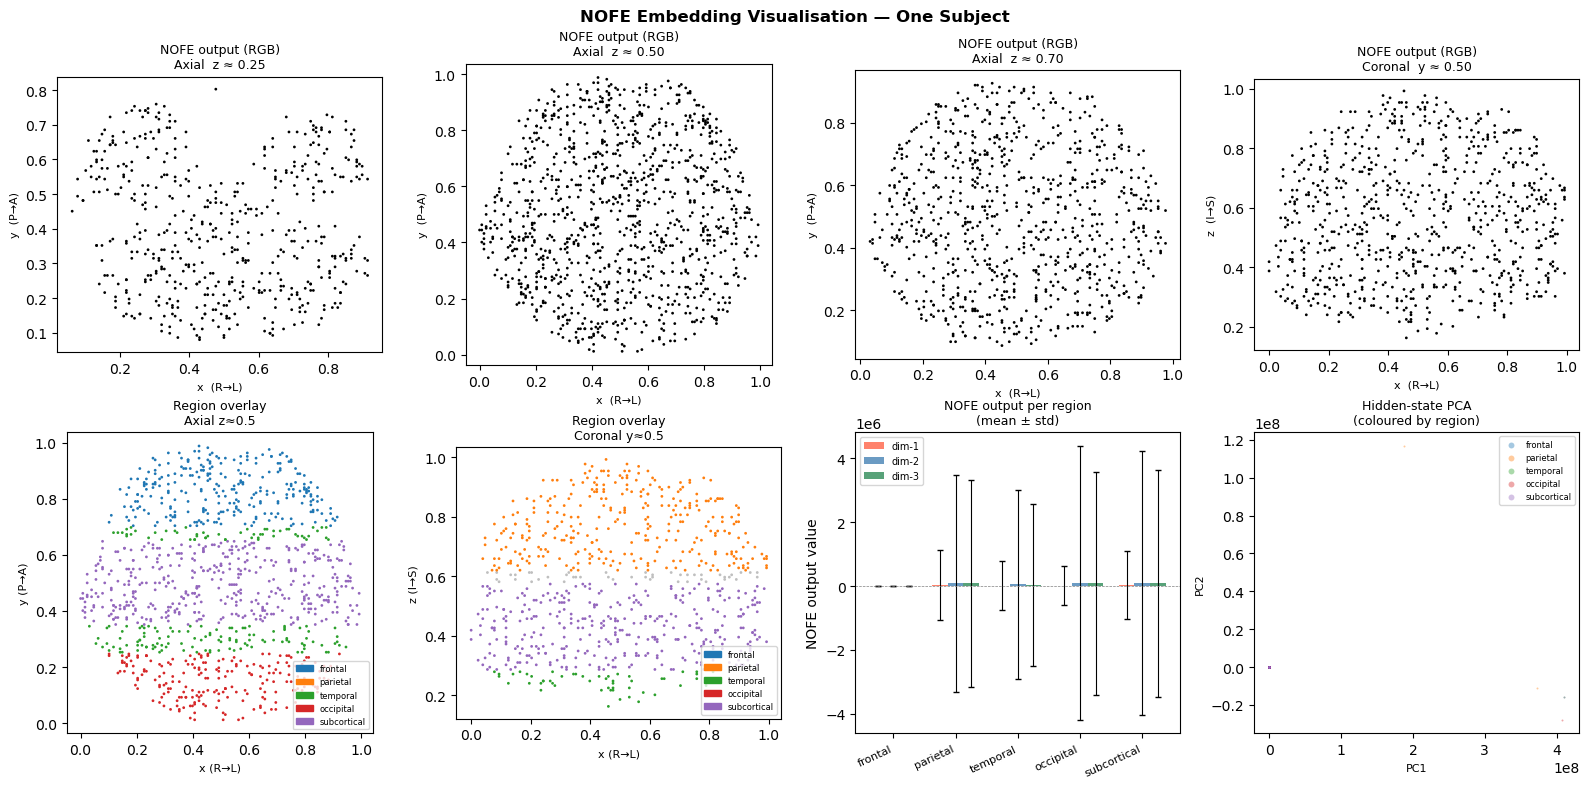

In [5]:
vis_hidden, vis_output, vis_coords = vis_data
masks_vis = region_masks(vis_coords)

# Normalise NOFE output [0,1] per channel → RGB
out_min = vis_output.min(axis=0)
out_max = vis_output.max(axis=0)
out_rgb = np.clip((vis_output - out_min) / (out_max - out_min + 1e-8), 0, 1)

# Region colour per voxel
vox_col = np.full((len(vis_coords), 3), 0.75)
for name in REGION_NAMES:
    c = mpatches.Patch(color=REGION_COLORS[name]).get_facecolor()[:3]
    vox_col[masks_vis[name]] = c

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
THICKNESS = 0.03

# ── Row 0: NOFE output as RGB, three axial slices + one coronal ──
for col, z_val in enumerate([0.25, 0.50, 0.70]):
    m  = np.abs(vis_coords[:, 2] - z_val) < THICKNESS
    ax = axes[0, col]
    if m.sum() > 10:
        ax.scatter(vis_coords[m, 0], vis_coords[m, 1],
                   c=out_rgb[m], s=4, linewidths=0, rasterized=True)
    ax.set_xlabel('x  (R→L)', fontsize=8)
    ax.set_ylabel('y  (P→A)', fontsize=8)
    ax.set_title(f'NOFE output (RGB)\nAxial  z ≈ {z_val:.2f}', fontsize=9)
    ax.set_aspect('equal')

m  = np.abs(vis_coords[:, 1] - 0.50) < THICKNESS
ax = axes[0, 3]
if m.sum() > 10:
    ax.scatter(vis_coords[m, 0], vis_coords[m, 2],
               c=out_rgb[m], s=4, linewidths=0, rasterized=True)
ax.set_xlabel('x  (R→L)', fontsize=8)
ax.set_ylabel('z  (I→S)', fontsize=8)
ax.set_title('NOFE output (RGB)\nCoronal  y ≈ 0.50', fontsize=9)
ax.set_aspect('equal')

# ── Row 1: region overlays ──
for ax_idx, (ax_axis, a0, a1, lbl_x, lbl_y, c_val, plane) in enumerate([
    (axes[1, 0], 0, 1, 'x (R→L)', 'y (P→A)', 2, 'Axial z≈0.5'),
    (axes[1, 1], 0, 2, 'x (R→L)', 'z (I→S)', 1, 'Coronal y≈0.5'),
]):
    m = np.abs(vis_coords[:, c_val] - 0.5) < THICKNESS
    if m.sum() > 10:
        ax_axis.scatter(vis_coords[m, a0], vis_coords[m, a1],
                        c=vox_col[m], s=4, linewidths=0, rasterized=True)
    ax_axis.set_xlabel(lbl_x, fontsize=8)
    ax_axis.set_ylabel(lbl_y, fontsize=8)
    ax_axis.set_title(f'Region overlay\n{plane}', fontsize=9)
    ax_axis.set_aspect('equal')
    handles = [mpatches.Patch(color=REGION_COLORS[n], label=n) for n in REGION_NAMES]
    ax_axis.legend(handles=handles, fontsize=6, loc='lower right', framealpha=0.8)

# ── Row 1 col 2: per-region NOFE output distribution ──
ax_bar = axes[1, 2]
x_off  = np.arange(len(REGION_NAMES))
bar_w  = 0.25
ch_colors = ['tomato', 'steelblue', 'seagreen']
for d, (ch, col) in enumerate(zip(['dim-1', 'dim-2', 'dim-3'], ch_colors)):
    means = [vis_output[masks_vis[n], d].mean() if masks_vis[n].sum() > 0 else 0
             for n in REGION_NAMES]
    stds  = [vis_output[masks_vis[n], d].std()  if masks_vis[n].sum() > 0 else 0
             for n in REGION_NAMES]
    ax_bar.bar(x_off + d * bar_w, means, bar_w, color=col, alpha=0.8, label=ch)
    ax_bar.errorbar(x_off + d * bar_w, means, yerr=stds,
                    fmt='none', color='black', capsize=2, lw=0.8)
ax_bar.set_xticks(x_off + bar_w)
ax_bar.set_xticklabels(REGION_NAMES, rotation=25, ha='right', fontsize=8)
ax_bar.set_ylabel('NOFE output value')
ax_bar.set_title('NOFE output per region\n(mean ± std)', fontsize=9)
ax_bar.legend(fontsize=7)
ax_bar.axhline(0, color='gray', lw=0.5, ls='--')

# ── Row 1 col 3: hidden-state PCA coloured by region ──
pca = PCA(n_components=2).fit(vis_hidden)
h2  = pca.transform(vis_hidden)
ax_pca = axes[1, 3]
for name in REGION_NAMES:
    m = masks_vis[name]
    if m.sum() > 0:
        ax_pca.scatter(h2[m, 0], h2[m, 1], c=REGION_COLORS[name],
                       s=2, alpha=0.4, linewidths=0, label=name, rasterized=True)
ax_pca.set_xlabel('PC1', fontsize=8)
ax_pca.set_ylabel('PC2', fontsize=8)
ax_pca.set_title('Hidden-state PCA\n(coloured by region)', fontsize=9)
ax_pca.legend(fontsize=6, markerscale=3, loc='best')

fig.suptitle('NOFE Embedding Visualisation — One Subject', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

In [6]:
csv_path = data_root / 'HCP_YA_subjects_2026_04_30_00_43_32.csv'
df       = pd.read_csv(csv_path)

SCORE_COLS = {
    'CardSort':  'CardSort_Unadj',
    'Flanker':   'Flanker_Unadj',
    'PMAT24':    'PMAT24_A_CR',
    'ProcSpeed': 'ProcSpeed_Unadj',
    'ListSort':  'ListSort_Unadj',
    'ReadEng':   'ReadEng_Unadj',
    'PicVocab':  'PicVocab_Unadj',
}
SCORE_GROUP = {
    'CardSort': 'Fluid',  'Flanker': 'Fluid',   'PMAT24':   'Fluid',
    'ProcSpeed':'Fluid',  'ListSort':'Fluid',
    'ReadEng':  'Crystallised', 'PicVocab': 'Crystallised',
}
GROUP_COLOR = {'Fluid': '#1f77b4', 'Crystallised': '#d62728'}

local_df = df[df['Subject'].isin(subject_ids)].set_index('Subject')
Y        = {name: local_df.loc[subject_ids, col].values.astype(float)
            for name, col in SCORE_COLS.items()}

print(f'Loaded {len(Y)} cognitive scores for {N_SUBJ} subjects:')
for name, y in Y.items():
    grp = SCORE_GROUP[name]
    print(f'  {name:12s} ({grp:13s}):  mean={y.mean():.1f}  std={y.std():.1f}')

Loaded 7 cognitive scores for 16 subjects:
  CardSort     (Fluid        ):  mean=114.4  std=11.4
  Flanker      (Fluid        ):  mean=109.3  std=7.5
  PMAT24       (Fluid        ):  mean=14.1  std=5.3
  ProcSpeed    (Fluid        ):  mean=115.5  std=17.9
  ListSort     (Fluid        ):  mean=109.3  std=12.2
  ReadEng      (Crystallised ):  mean=118.2  std=12.1
  PicVocab     (Crystallised ):  mean=113.9  std=10.1


## 4. Representational Dissimilarity Matrices (RDMs)

An **RDM** is an N × N symmetric matrix where entry (i, j) quantifies how different
subjects i and j are in a given representational space.

| RDM | Distance metric | Meaning |
|---|---|---|
| Brain (whole-brain) | Cosine distance on 32-D vector | Global white-matter representational difference |
| Brain (per-region) | Cosine distance on 32-D vector | Regional white-matter difference |
| Cognitive score | Absolute difference \|y_i − y_j\| | Cognitive performance difference |

**RSA** then asks: is the geometry of the brain RDM correlated with the geometry
of a cognitive RDM?  If yes → subjects who are similar in NOFE representation
are also similar in cognition.

In [7]:
def make_brain_rdm(X, metric='cosine'):
    """Pairwise cosine distance between subject embedding vectors."""
    return squareform(pdist(X, metric=metric))


def make_score_rdm(y):
    """Pairwise absolute difference for a scalar cognitive score."""
    y = np.asarray(y, dtype=float).reshape(-1, 1)
    return np.abs(y - y.T)


# Brain RDMs
RDM_whole  = make_brain_rdm(X_whole)
RDM_by_reg = {n: make_brain_rdm(X_region[:, i, :])
              for i, n in enumerate(REGION_NAMES)}

# Cognitive RDMs
RDM_scores = {name: make_score_rdm(y) for name, y in Y.items()}

print(f'Brain RDM (whole)    : {RDM_whole.shape}')
print(f'Brain RDM (per region): {list(RDM_by_reg.values())[0].shape}')
print(f'Cognitive RDM        : {list(RDM_scores.values())[0].shape}')
print(f'Unique pairs in lower triangle: {(N_SUBJ*(N_SUBJ-1))//2}')

Brain RDM (whole)    : (16, 16)
Brain RDM (per region): (16, 16)
Cognitive RDM        : (16, 16)
Unique pairs in lower triangle: 120


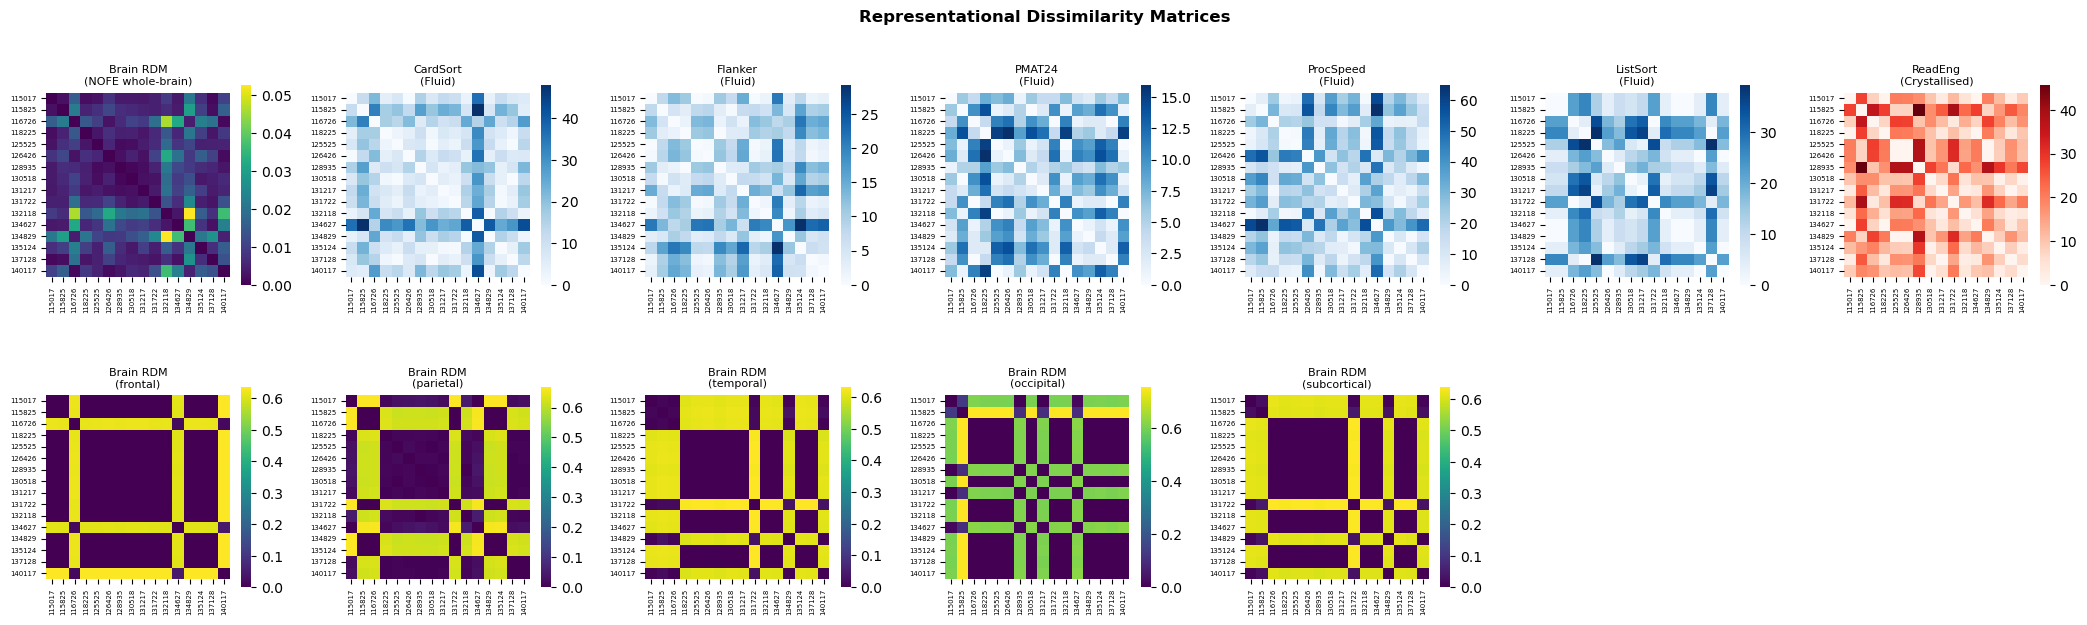

In [8]:
score_names = list(SCORE_COLS.keys())
subj_labels = [str(s) for s in subject_ids]
n_scores    = len(score_names)

fig, axes = plt.subplots(2, n_scores, figsize=(3 * n_scores, 6.5))

# Row 0: whole-brain RDM + best cognitive RDMs (fluid)
rdm_top = [('Brain RDM\n(NOFE whole-brain)', RDM_whole, 'viridis')]
for s in score_names:
    cmap = 'Blues' if SCORE_GROUP[s] == 'Fluid' else 'Reds'
    rdm_top.append((f'{s}\n({SCORE_GROUP[s]})', RDM_scores[s], cmap))

for ax, (title, rdm, cmap) in zip(axes[0], rdm_top[:n_scores]):
    sns.heatmap(rdm, ax=ax, cmap=cmap, square=True, cbar=True,
                xticklabels=subj_labels, yticklabels=subj_labels,
                cbar_kws={'shrink': 0.7})
    ax.set_title(title, fontsize=8)
    ax.tick_params(labelsize=5)

# Row 1: per-region brain RDMs
for ax, name in zip(axes[1], REGION_NAMES):
    sns.heatmap(RDM_by_reg[name], ax=ax, cmap='viridis', square=True, cbar=True,
                xticklabels=subj_labels, yticklabels=subj_labels,
                cbar_kws={'shrink': 0.7})
    ax.set_title(f'Brain RDM\n({name})', fontsize=8)
    ax.tick_params(labelsize=5)

for ax in axes[1, len(REGION_NAMES):]:
    ax.set_visible(False)

fig.suptitle('Representational Dissimilarity Matrices', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

## 5. Representational Similarity Analysis

### Procedure

1. Extract the **lower triangle** of each pair of RDMs (120 unique values for n = 16)
2. Compute **Spearman ρ** between the brain-dissimilarity vector and the cognitive-dissimilarity vector
3. Test significance with a **Mantel permutation test**:
   - Randomly permute the row/column order of the brain RDM 5 000 times
   - Build a null distribution of ρ under H₀ (no relationship)
   - p-value = fraction of permutations with ρ ≥ observed ρ

### Comparisons

We test **6 brain representations** × **7 cognitive scores** = **42 comparisons**.

Brain representations:
- `Whole` — global mean-pool (32-D)
- `Frontal`, `Parietal`, `Temporal`, `Occipital`, `Subcortical` — regional mean-pool (32-D each)

A positive ρ means: pairs of subjects who are more different in NOFE embedding
are also more different in cognitive score.

In [9]:
def mantel_test(rdm_a, rdm_b, n_perm=5000, seed=42):
    """
    Spearman correlation between lower triangles of two RDMs.
    Significance via row/column permutation of rdm_a.
    Returns: r_obs (float), p_val (float), r_null (array).
    """
    n   = rdm_a.shape[0]
    idx = np.tril_indices(n, k=-1)
    va  = rdm_a[idx]
    vb  = rdm_b[idx]
    r_obs, _ = spearmanr(va, vb)

    rng    = np.random.default_rng(seed)
    r_null = np.empty(n_perm)
    for i in range(n_perm):
        perm       = rng.permutation(n)
        r_null[i], _ = spearmanr(rdm_a[np.ix_(perm, perm)][idx], vb)

    p_val = float((r_null >= r_obs).mean())
    return r_obs, p_val, r_null


BRAIN_RDMS = {'Whole': RDM_whole, **{n.capitalize(): RDM_by_reg[n] for n in REGION_NAMES}}

rsa = {}
print(f'  {"Brain rep":14s}  {"Score":12s}  {"r":>7s}  {"p":>7s}')
print('  ' + '-' * 48)
for brain_label, rdm_b in BRAIN_RDMS.items():
    rsa[brain_label] = {}
    for score_name, rdm_c in RDM_scores.items():
        r, p, null = mantel_test(rdm_b, rdm_c)
        rsa[brain_label][score_name] = {'r': r, 'p': p, 'null': null}
        sig = ' ***' if p < 0.001 else ' **' if p < 0.01 else ' *' if p < 0.05 else ''
        print(f'  {brain_label:14s}  {score_name:12s}  {r:+.3f}  {p:.3f}{sig}')
    print()

  Brain rep       Score               r        p
  ------------------------------------------------
  Whole           CardSort      +0.185  0.096
  Whole           Flanker       -0.069  0.689
  Whole           PMAT24        -0.033  0.594
  Whole           ProcSpeed     +0.018  0.400
  Whole           ListSort      -0.159  0.931
  Whole           ReadEng       -0.069  0.694
  Whole           PicVocab      -0.011  0.509

  Frontal         CardSort      +0.386  0.021 *
  Frontal         Flanker       +0.127  0.172
  Frontal         PMAT24        -0.023  0.552
  Frontal         ProcSpeed     +0.013  0.425
  Frontal         ListSort      +0.066  0.280
  Frontal         ReadEng       +0.014  0.414
  Frontal         PicVocab      +0.089  0.239

  Parietal        CardSort      +0.107  0.140
  Parietal        Flanker       +0.002  0.421
  Parietal        PMAT24        +0.026  0.286
  Parietal        ProcSpeed     +0.092  0.166
  Parietal        ListSort      -0.067  0.750
  Parietal        Read

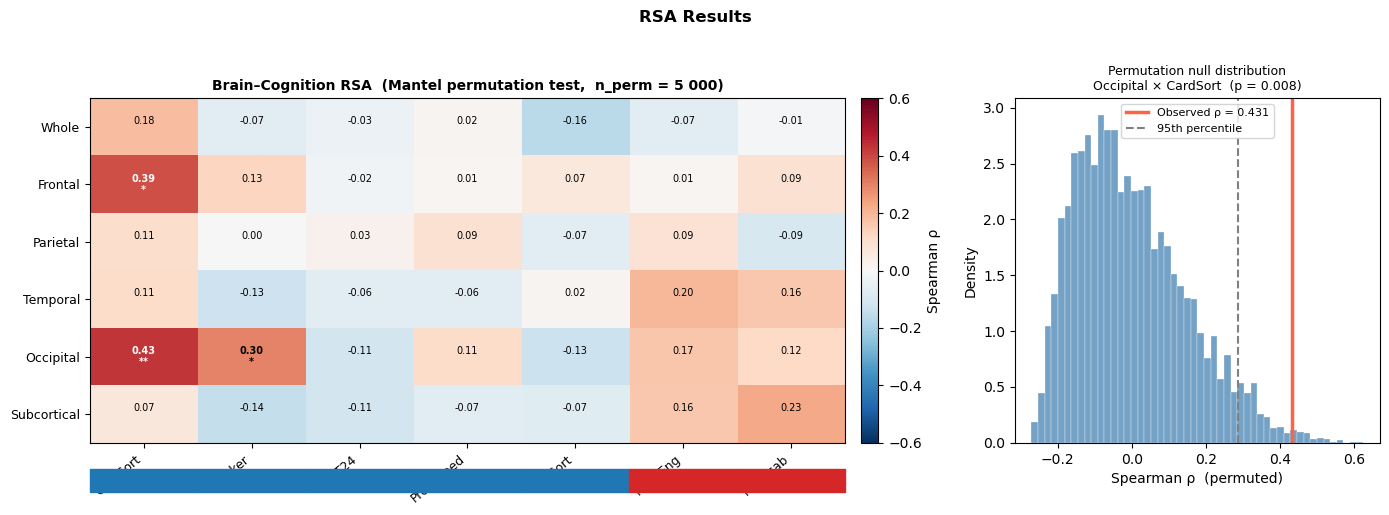

In [10]:
brain_labels = list(BRAIN_RDMS.keys())
score_labels = list(SCORE_COLS.keys())

r_mat = np.array([[rsa[b][s]['r'] for s in score_labels] for b in brain_labels])
p_mat = np.array([[rsa[b][s]['p'] for s in score_labels] for b in brain_labels])

fig, axes = plt.subplots(1, 2, figsize=(14, 5),
                          gridspec_kw={'width_ratios': [2.2, 1]})

# ── Left: r-value heatmap ──
ax = axes[0]
im = ax.imshow(r_mat, cmap='RdBu_r', vmin=-0.6, vmax=0.6, aspect='auto')
plt.colorbar(im, ax=ax, label='Spearman ρ', fraction=0.04, pad=0.02)

ax.set_xticks(range(len(score_labels)))
ax.set_xticklabels(score_labels, rotation=40, ha='right', fontsize=9)
ax.set_yticks(range(len(brain_labels)))
ax.set_yticklabels(brain_labels, fontsize=9)
ax.set_title('Brain–Cognition RSA  (Mantel permutation test,  n_perm = 5 000)',
             fontsize=10, fontweight='bold')

for i in range(len(brain_labels)):
    for j in range(len(score_labels)):
        r   = r_mat[i, j]
        p   = p_mat[i, j]
        sig = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else ''
        col = 'white' if abs(r) > 0.35 else 'black'
        ax.text(j, i, f'{r:.2f}\n{sig}', ha='center', va='center',
                fontsize=7, color=col,
                fontweight='bold' if sig else 'normal')

# Colour-coded column headers (fluid = blue, crystallised = red)
for j, s in enumerate(score_labels):
    col = GROUP_COLOR[SCORE_GROUP[s]]
    ax.add_patch(plt.Rectangle(
        (j - 0.5, len(brain_labels) - 0.05), 1, 0.4,
        color=col, clip_on=False, transform=ax.transData, zorder=3))

# ── Right: permutation null for the best cell ──
best_ij   = np.unravel_index(r_mat.argmax(), r_mat.shape)
b_best    = brain_labels[best_ij[0]]
s_best    = score_labels[best_ij[1]]
best      = rsa[b_best][s_best]

ax2 = axes[1]
ax2.hist(best['null'], bins=50, color='steelblue', alpha=0.75,
         density=True, edgecolor='white', linewidth=0.3)
ax2.axvline(best['r'], color='tomato', lw=2.5,
            label=f'Observed ρ = {best["r"]:.3f}')
ax2.axvline(np.percentile(best['null'], 95), color='gray', lw=1.5, ls='--',
            label='95th percentile')
ax2.set_xlabel('Spearman ρ  (permuted)')
ax2.set_ylabel('Density')
ax2.set_title(f'Permutation null distribution\n'
              f'{b_best} × {s_best}  (p = {best["p"]:.3f})', fontsize=9)
ax2.legend(fontsize=8)

fig.suptitle('RSA Results', fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

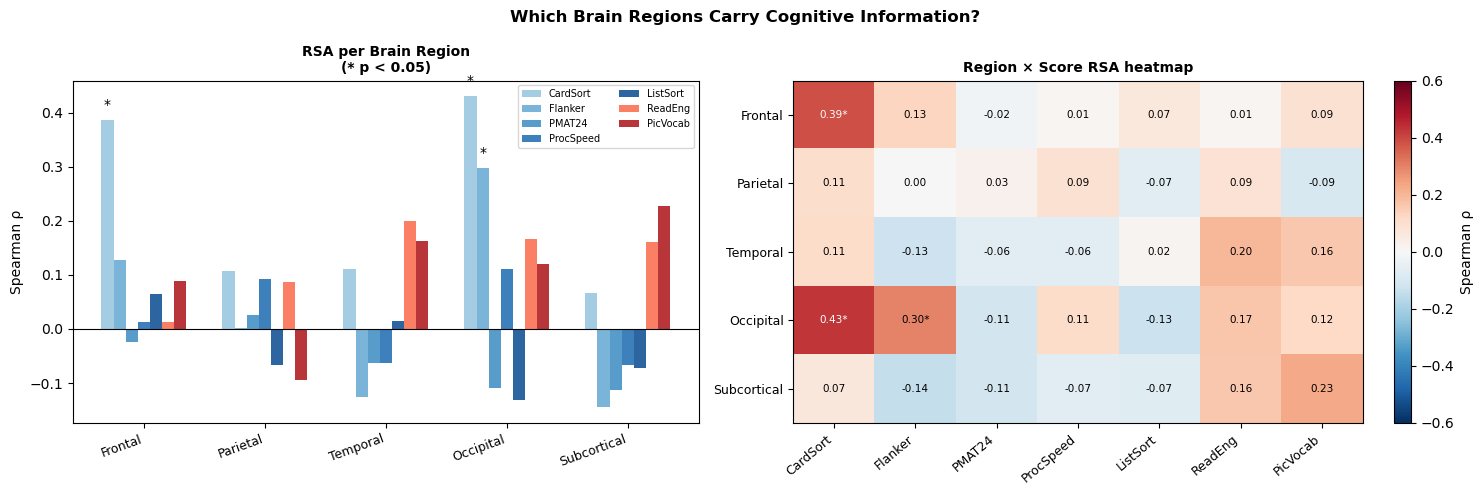

In [11]:
region_labels = [b for b in brain_labels if b != 'Whole']
n_regions     = len(region_labels)
n_scores      = len(score_labels)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# ── Left: grouped bar (x = region, grouped by score) ──
x     = np.arange(n_regions)
width = 0.10
fluid_c   = plt.cm.Blues(np.linspace(0.4, 0.9, 5))
crystal_c = plt.cm.Reds(np.linspace(0.5, 0.85, 2))
bar_colors = list(fluid_c) + list(crystal_c)

ax = axes[0]
for i, score in enumerate(score_labels):
    vals = [rsa[reg][score]['r'] for reg in region_labels]
    ax.bar(x + i * width, vals, width,
           color=bar_colors[i], alpha=0.85, label=score)
    for j, (v, reg) in enumerate(zip(vals, region_labels)):
        if rsa[reg][score]['p'] < 0.05:
            ypos = v + (0.015 if v >= 0 else -0.04)
            ax.text(x[j] + i * width, ypos, '*',
                    ha='center', va='bottom', fontsize=10)

ax.set_xticks(x + width * (n_scores - 1) / 2)
ax.set_xticklabels(region_labels, rotation=20, ha='right', fontsize=9)
ax.axhline(0, color='black', lw=0.8)
ax.set_ylabel('Spearman ρ')
ax.set_title('RSA per Brain Region\n(* p < 0.05)', fontsize=10, fontweight='bold')
ax.legend(fontsize=7, ncol=2, loc='upper right')

# ── Right: region × score heatmap ──
ax2   = axes[1]
r_reg = np.array([[rsa[reg][s]['r'] for s in score_labels] for reg in region_labels])
p_reg = np.array([[rsa[reg][s]['p'] for s in score_labels] for reg in region_labels])
im    = ax2.imshow(r_reg, cmap='RdBu_r', vmin=-0.6, vmax=0.6, aspect='auto')
plt.colorbar(im, ax=ax2, label='Spearman ρ', fraction=0.04)
ax2.set_xticks(range(n_scores))
ax2.set_xticklabels(score_labels, rotation=40, ha='right', fontsize=9)
ax2.set_yticks(range(n_regions))
ax2.set_yticklabels(region_labels, fontsize=9)
ax2.set_title('Region × Score RSA heatmap', fontsize=10, fontweight='bold')
for i in range(n_regions):
    for j in range(n_scores):
        sig = '*' if p_reg[i, j] < 0.05 else ''
        col = 'white' if abs(r_reg[i, j]) > 0.35 else 'black'
        ax2.text(j, i, f'{r_reg[i,j]:.2f}{sig}',
                 ha='center', va='center', fontsize=7.5, color=col)

fig.suptitle('Which Brain Regions Carry Cognitive Information?', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

## 6. Conclusions

### How to read the results

| RSA outcome | Interpretation |
|---|---|
| ρ > 0, p < 0.05 | NOFE captures cognitively relevant microstructure in that region |
| ρ > 0, p > 0.05 | Positive trend, but underpowered (n = 16) |
| ρ ≈ 0 | Mean-pooling loses the relevant signal in that region |
| ρ < 0 | Unlikely — would mean similar brains → more different cognition |

### Implications

**If significant regions exist:**
NOFE's unsupervised embedding encodes microstructural variation that is correlated
with individual differences in cognition.
This validates the use of NOFE features as input to a cognitive prediction pipeline
and confirms that the brain-region decomposition is biologically meaningful.

**If no significant regions:**
The current base model (40 K params, `channel_only` input, epoch-70 saturation)
produces an embedding where mean-pooling discards the cognitively relevant signal.
The natural next step is **Plan B** — the `large_wPos` model (146-D input with
position, w64 / kw128 / d6) — which should produce a richer, more structured embedding.

### Limitations
- n = 16 limits power; even with RSA, p-values should be interpreted cautiously
- Coordinate-based region approximation is coarse (no atlas)
- NOFE was not trained to discriminate between subjects

  RSA SUMMARY
  Significant pairs (p < 0.05): 3 / 42
  Best result: Occipital x CardSort  rho=0.431  p=0.008

  Best region per cognitive score:
    CardSort      →  Occipital       rho=0.431  p=0.008 *
    Flanker       →  Occipital       rho=0.298  p=0.026 *
    PMAT24        →  Parietal        rho=0.026  p=0.286
    ProcSpeed     →  Occipital       rho=0.112  p=0.187
    ListSort      →  Frontal         rho=0.066  p=0.280
    ReadEng       →  Temporal        rho=0.200  p=0.061
    PicVocab      →  Subcortical     rho=0.228  p=0.053


/var/folders/px/747r5b694x947qk1vdh9b3th0000gp/T/ipykernel_87877/3049213057.py:57: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(sig_counts.keys(), rotation=30, ha='right', fontsize=9)


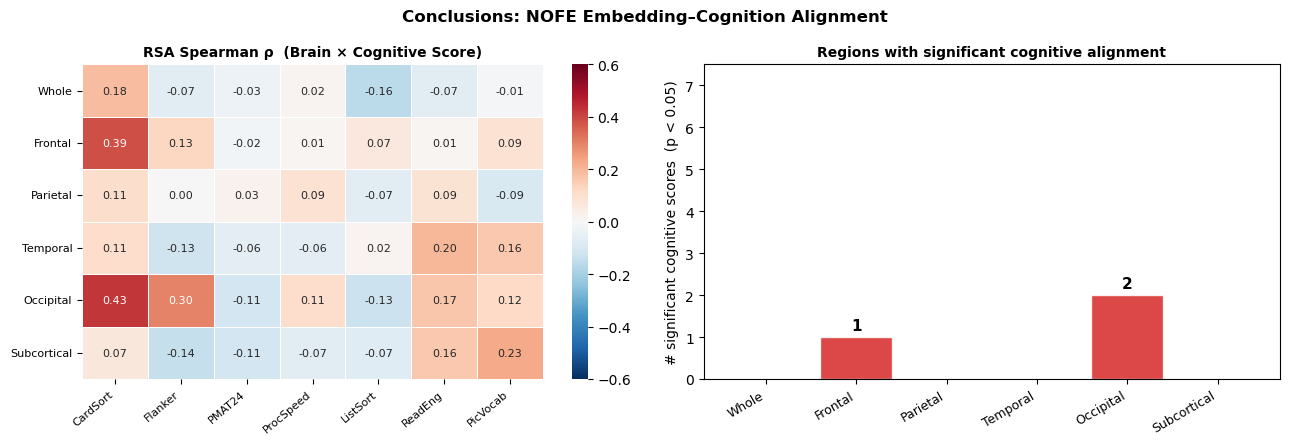

In [12]:
# ── Auto-generate conclusions from results ──
sig_pairs = [(b, s) for b in brain_labels for s in score_labels
             if rsa[b][s]['p'] < 0.05]

best_ij   = np.unravel_index(r_mat.argmax(), r_mat.shape)
b_best    = brain_labels[best_ij[0]]
s_best    = score_labels[best_ij[1]]
r_best    = rsa[b_best][s_best]['r']
p_best    = rsa[b_best][s_best]['p']

print('=' * 55)
print('  RSA SUMMARY')
print('=' * 55)
print(f'  Significant pairs (p < 0.05): {len(sig_pairs)} / '
      f'{len(brain_labels) * len(score_labels)}')
print(f'  Best result: {b_best} x {s_best}  '
      f'rho={r_best:.3f}  p={p_best:.3f}')
print()
print('  Best region per cognitive score:')
for s in score_labels:
    b_top = max(brain_labels, key=lambda b: rsa[b][s]['r'])
    r_top = rsa[b_top][s]['r']
    p_top = rsa[b_top][s]['p']
    sig   = ' *' if p_top < 0.05 else ''
    print(f'    {s:12s}  →  {b_top:14s}  rho={r_top:.3f}  p={p_top:.3f}{sig}')

# ── Summary visualisation ──
rows = [{'Score': s, 'Group': SCORE_GROUP[s], 'Region': b,
          'rho': rsa[b][s]['r'], 'p': rsa[b][s]['p']}
        for b in brain_labels for s in score_labels]
df_res = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Left: full rho heatmap (seaborn — annotated)
pivot = df_res.pivot(index='Region', columns='Score', values='rho')
pivot = pivot.loc[brain_labels, score_labels]
sns.heatmap(pivot, ax=axes[0], cmap='RdBu_r', center=0, vmin=-0.6, vmax=0.6,
            annot=True, fmt='.2f', annot_kws={'size': 8},
            linewidths=0.4, linecolor='white')
axes[0].set_title('RSA Spearman ρ  (Brain × Cognitive Score)',
                  fontsize=10, fontweight='bold')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=40, ha='right', fontsize=8)
axes[0].set_yticklabels(axes[0].get_yticklabels(), rotation=0, fontsize=8)
axes[0].set_xlabel('')
axes[0].set_ylabel('')

# Right: count of significant scores per brain representation
sig_counts = {b: sum(1 for s in score_labels if rsa[b][s]['p'] < 0.05)
              for b in brain_labels}
bar_colors = ['#d62728' if v > 0 else '#aec7e8' for v in sig_counts.values()]
bars = axes[1].bar(sig_counts.keys(), sig_counts.values(),
                   color=bar_colors, alpha=0.85, edgecolor='white')
axes[1].set_ylabel('# significant cognitive scores  (p < 0.05)')
axes[1].set_title('Regions with significant cognitive alignment',
                  fontsize=10, fontweight='bold')
axes[1].set_xticklabels(sig_counts.keys(), rotation=30, ha='right', fontsize=9)
axes[1].axhline(0, color='black', lw=0.5)
axes[1].set_ylim(0, len(score_labels) + 0.5)
for bar, v in zip(bars, sig_counts.values()):
    if v > 0:
        axes[1].text(bar.get_x() + bar.get_width() / 2, v + 0.1,
                     str(v), ha='center', va='bottom', fontsize=11, fontweight='bold')

fig.suptitle('Conclusions: NOFE Embedding–Cognition Alignment', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()